In [3]:
%load_ext autoreload
%autoreload 2

from matplotlib import pyplot as plt
import numpy as np
from helpers import *
import math
import scipy

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Naloga 1. Zveza med Bernsteinovo in potenčno bazo

In [308]:
p = np.array([4,7,2,8,9,1,4]) # koeficienti od x^n do 1

b = power2bernstein(p)
b

array([ 4.        ,  4.16666667,  4.93333333,  6.7       , 10.        ,
       16.66666667, 35.        ])

In [311]:
p = bernstein2power(b)
p

array([4., 7., 2., 8., 9., 1., 4.])

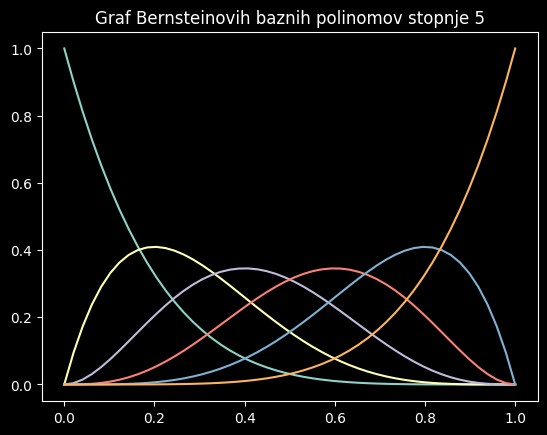

In [320]:
N = 5
x = np.linspace(0, 1)
plt.title("Graf Bernsteinovih baznih polinomov stopnje 5")
for i in range(N+1):
	b = np.zeros(N+1)
	b[i] = 1
	p = bernstein2power(b)
	plt.plot(x, np.polyval(p, x))

### Naloga 2. De Casteljaujev postopek

In [228]:
B = np.array([[0,0],[1,2],[3,3],[4,-1],[0,2]])
b = B[:,0]
decasteljau_basic(b, 1)

array([[ 0.,  1.,  3.,  4.,  0.],
       [ 1.,  3.,  4.,  0., nan],
       [ 3.,  4.,  0., nan, nan],
       [ 4.,  0., nan, nan, nan],
       [ 0., nan, nan, nan, nan]])

In [229]:
decasteljau(b, 1)

array([[[[ 0.,  1.,  3.,  4.,  0.],
         [ 1.,  3.,  4.,  0., nan],
         [ 3.,  4.,  0., nan, nan],
         [ 4.,  0., nan, nan, nan],
         [ 0., nan, nan, nan, nan]]]])

In [232]:
decasteljau(B, 0)

array([[[[ 0.,  0.,  0.,  0.,  0.],
         [ 1.,  1.,  1.,  1., nan],
         [ 3.,  3.,  3., nan, nan],
         [ 4.,  4., nan, nan, nan],
         [ 0., nan, nan, nan, nan]],

        [[ 0.,  0.,  0.,  0.,  0.],
         [ 2.,  2.,  2.,  2., nan],
         [ 3.,  3.,  3., nan, nan],
         [-1., -1., nan, nan, nan],
         [ 2., nan, nan, nan, nan]]]])

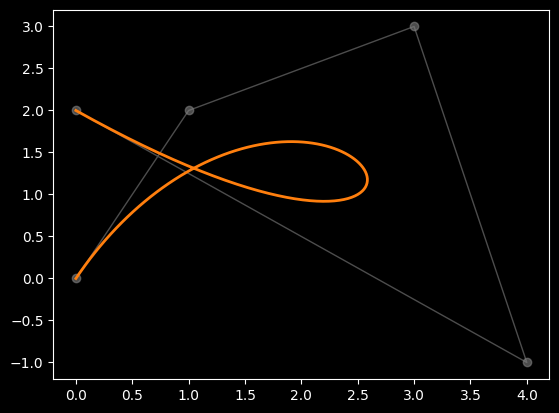

In [261]:
B = np.array([[0,0],[1,2],[3,3],[4,-1],[0,2]])
t = np.linspace(0,1,100)

plotbezier(B, t, "tab:orange")

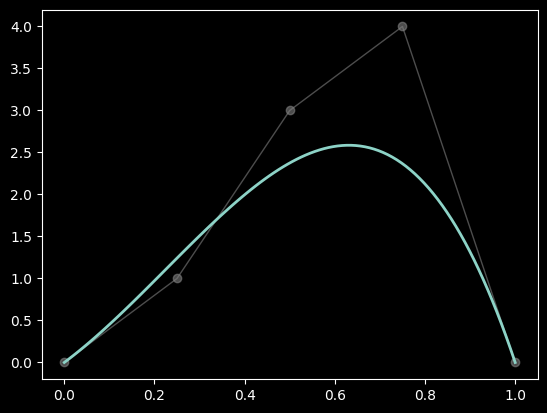

In [262]:
plotbezier(B[:,0], t)

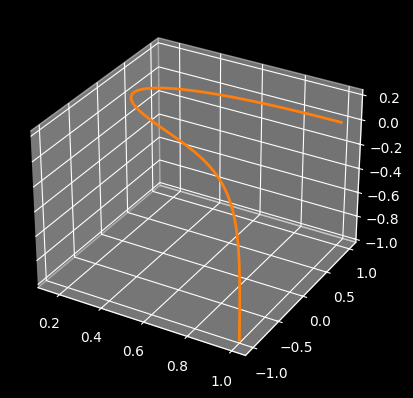

In [272]:
B = np.array([
	[1,1,0],
	[-1,1,0],
	[1,-1,0],
	[1,-1,1],
	[1,-1,-1]
])

t = np.linspace(0, 1, 100)

plotbezier(B, t, "tab:orange", controls=False)

### Naloga 3. Odvodi Bezierjeve krivulje

In [ ]:
B = np.array([[-2/3,-4/5],[1/3,1/5],[0,0],[-1/3,1/5],[2/3,-4/5]])
t = np.linspace(0,1,9)

bezierder(B,1,t) # TODO: preveri ali je dovolj natančna

(array([[ 4.00000000e+00,  4.00000000e+00],
        [ 2.25000000e+00,  2.47500000e+00],
        [ 1.00000000e+00,  1.40000000e+00],
        [ 2.50000000e-01,  6.25000000e-01],
        [ 1.11022302e-16,  0.00000000e+00],
        [ 2.50000000e-01, -6.25000000e-01],
        [ 1.00000000e+00, -1.40000000e+00],
        [ 2.25000000e+00, -2.47500000e+00],
        [ 4.00000000e+00, -4.00000000e+00]]),
 array([[ 4.        ,  4.        ],
        [-1.33333333, -0.8       ],
        [-1.33333333,  0.8       ],
        [ 4.        , -4.        ]]))

In [364]:
t = np.arange(0.46,0.54,0.01)
d1b, _ = bezierder(B, 1, t)
R = np.hstack((t.reshape(-1,1), d1b))

with np.printoptions(precision=4, suppress=True):
	print(R)

[[ 0.46    0.0256  0.1928]
 [ 0.47    0.0144  0.1443]
 [ 0.48    0.0064  0.0961]
 [ 0.49    0.0016  0.048 ]
 [ 0.5     0.      0.    ]
 [ 0.51    0.0016 -0.048 ]
 [ 0.52    0.0064 -0.0961]
 [ 0.53    0.0144 -0.1443]
 [ 0.54    0.0256 -0.1928]]


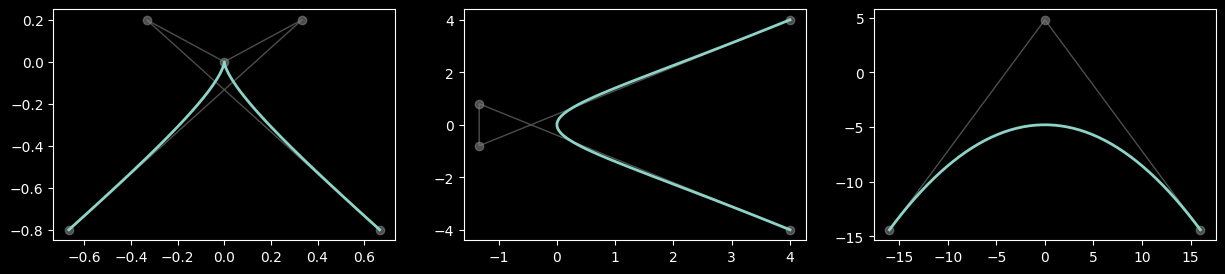

In [ ]:
t = np.linspace(0, 1)
d1b, d1B = bezierder(B,1,t)
d2b, d2B = bezierder(B,2,t)

plt.figure(figsize=(15,3))
plt.subplot(1, 3, 1)
plotbezier(B, t)
plt.subplot(1, 3, 2)
plotbezier(d1B, t)
plt.subplot(1, 3, 3)
plotbezier(d2B, t)

### Naloga 4. Opis krožnice z Bezierjevimi krivuljami

[[ 0.80901699 -0.58778525]
 [ 1.23606798  0.        ]
 [ 0.80901699  0.58778525]]
[[ 0.80901699 -0.58778525]
 [ 1.00494541 -0.31811292]
 [ 1.00494541  0.31811292]
 [ 0.80901699  0.58778525]]
[[ 0.80901699 -0.58778525]
 [ 1.063661   -0.23729784]
 [ 1.063661    0.23729784]
 [ 0.80901699  0.58778525]]
e1 = 0.022542485937368628
e2 = 0.04403669255193421
e3 = 7.130701741275836e-05


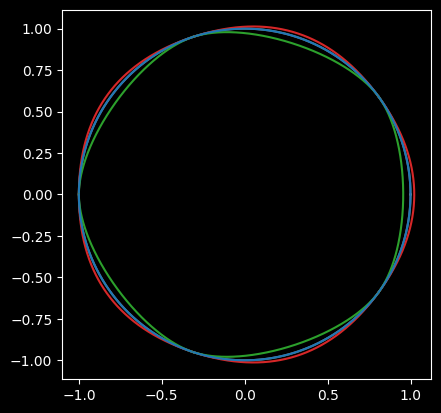

In [400]:
N = 5
fi = np.pi/N

B1 = bezierarc(fi, 1)
print(B1)
B2 = bezierarc(fi, 2)
print(B2)
B3 = bezierarc(fi, 3)
print(B3)

t = np.linspace(0, 1, 10001)
b1 = bezier(B1, t)
b2 = bezier(B2, t)
b3 = bezier(B3, t)

print(f"e1 = {np.max(np.abs(1 - np.linalg.norm(b1, axis=1)))}")
print(f"e2 = {np.max(np.abs(1 - np.linalg.norm(b2, axis=1)))}")
print(f"e3 = {np.max(np.abs(1 - np.linalg.norm(b3, axis=1)))}")

c = np.cos(2*fi)
s = np.sin(2*fi)
R = np.array([[c, -s],[s, c]])

plt.plot(np.cos(2*np.pi*t), np.sin(2*np.pi*t), color="gray")

for _ in range(N):
	b1 = (R @ b1.T).T
	b2 = (R @ b2.T).T
	b3 = (R @ b3.T).T
	plt.plot(b1[:,0], b1[:,1], color="tab:red")
	plt.plot(b2[:,0], b2[:,1], color="tab:green")
	plt.plot(b3[:,0], b3[:,1], color="tab:blue")
	
plt.gca().set_aspect('equal')

### Naloga 5. Subdivizija Bezierjeve krivulje

In [439]:
B = np.array([[0,0],[2,3],[4,2],[5,-1]])

beziersub(B, 0.5, 3)

[array([[0.        , 0.        ],
        [0.25      , 0.375     ],
        [0.5       , 0.6875    ],
        [0.74804688, 0.94140625]]),
 array([[0.74804688, 0.94140625],
        [0.99609375, 1.1953125 ],
        [1.2421875 , 1.390625  ],
        [1.484375  , 1.53125   ]]),
 array([[1.484375  , 1.53125   ],
        [1.7265625 , 1.671875  ],
        [1.96484375, 1.7578125 ],
        [2.19726562, 1.79296875]]),
 array([[2.19726562, 1.79296875],
        [2.4296875 , 1.828125  ],
        [2.65625   , 1.8125    ],
        [2.875     , 1.75      ]]),
 array([[2.875     , 1.75      ],
        [3.09375   , 1.6875    ],
        [3.3046875 , 1.578125  ],
        [3.50585938, 1.42578125]]),
 array([[3.50585938, 1.42578125],
        [3.70703125, 1.2734375 ],
        [3.8984375 , 1.078125  ],
        [4.078125  , 0.84375   ]]),
 array([[4.078125  , 0.84375   ],
        [4.2578125 , 0.609375  ],
        [4.42578125, 0.3359375 ],
        [4.58007812, 0.02734375]]),
 array([[ 4.58007812,  0.02734375]

### Naloga 6. Višanje stopnje Bezierjeve krivulje

### Naloga 7. Parametrizacija sestavljene krivulje

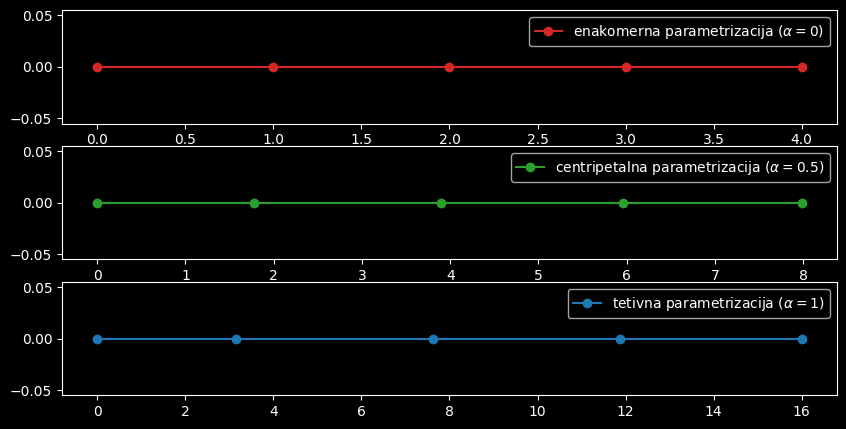

In [18]:
P = np.array([[-5,0],[-2,-1],[0,3],[3,0],[7,-1]])

ue = alphaparam(P, 0)
uc = alphaparam(P, 0.5)
ut = alphaparam(P, 1)
z = np.zeros(5)
plt.figure(figsize=(10, 5))
plt.subplot(3, 1, 1)
plt.plot(ue, z, '-o', label='enakomerna parametrizacija ($\\alpha = 0$)', color='tab:red')
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(uc, z, '-o', label='centripetalna parametrizacija ($\\alpha = 0.5$)', color='tab:green')
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(ut, z, '-o', label='tetivna parametrizacija ($\\alpha = 1$)', color='tab:blue')
plt.legend()

### Naloga 8

In [52]:
D = np.array([[-5,0],[-4,1],[-2,-1],[0,3],[3,0],[5,2],[7,-1]])
P = D[[0, 2, 3, 4, 6]]

ue = alphaparam(P, 0)
Be = beziercubspline(ue, D)

In [56]:
Be 

[array([[-5.        ,  0.        ],
        [-4.        ,  1.        ],
        [-3.        ,  0.        ],
        [-2.16666667,  0.16666667]]),
 array([[-2.16666667,  0.16666667],
        [-1.33333333,  0.33333333],
        [-0.66666667,  1.66666667],
        [ 0.16666667,  1.83333333]]),
 array([[0.16666667, 1.83333333],
        [1.        , 2.        ],
        [2.        , 1.        ],
        [3.        , 1.        ]]),
 array([[ 3.,  1.],
        [ 4.,  1.],
        [ 5.,  2.],
        [ 7., -1.]])]

### Naloga 9

In [385]:
B = matlab_to_numpy("[0 0; 2 3; 5 0; 3 -1; 2 -1]")
w = matlab_to_numpy("[0.5; 0.7; 0.8; 1; 0.6]")
t = np.linspace(0, 1, 10)

P = rbezier(B, w, t)
print(P)

[[ 0.          0.        ]
 [ 1.17768357  1.1169205 ]
 [ 2.15024327  1.2870545 ]
 [ 2.85223368  1.00687285]
 [ 3.26626004  0.54606107]
 [ 3.4107915   0.05884565]
 [ 3.32436472 -0.37070254]
 [ 3.04918529 -0.70209066]
 [ 2.61389251 -0.91784023]
 [ 2.         -1.        ]]


In [386]:
w1 = w.copy()
w1[1] = 0.7

P1 = rbezier(B, w1, t)
print(P1)

[[ 0.          0.        ]
 [ 1.17768357  1.1169205 ]
 [ 2.15024327  1.2870545 ]
 [ 2.85223368  1.00687285]
 [ 3.26626004  0.54606107]
 [ 3.4107915   0.05884565]
 [ 3.32436472 -0.37070254]
 [ 3.04918529 -0.70209066]
 [ 2.61389251 -0.91784023]
 [ 2.         -1.        ]]


In [389]:
w2 = w.copy()
w2[1] = 2
rbezier(B, w2, t)

array([[ 0.        ,  0.        ],
       [ 1.51534594,  1.89015701],
       [ 2.08208167,  2.0641748 ],
       [ 2.49699399,  1.83767535],
       [ 2.83680098,  1.37832796],
       [ 3.07460977,  0.75970213],
       [ 3.1461837 ,  0.08279431],
       [ 2.99444584, -0.50894041],
       [ 2.60865643, -0.88442376],
       [ 2.        , -1.        ]])

In [390]:
w3 = w.copy()
w3[1] = 0.2
rbezier(B, w2, t)

array([[ 0.        ,  0.        ],
       [ 1.51534594,  1.89015701],
       [ 2.08208167,  2.0641748 ],
       [ 2.49699399,  1.83767535],
       [ 2.83680098,  1.37832796],
       [ 3.07460977,  0.75970213],
       [ 3.1461837 ,  0.08279431],
       [ 2.99444584, -0.50894041],
       [ 2.60865643, -0.88442376],
       [ 2.        , -1.        ]])

Text(0.5, 1.0, 'w[1] = 0.2')

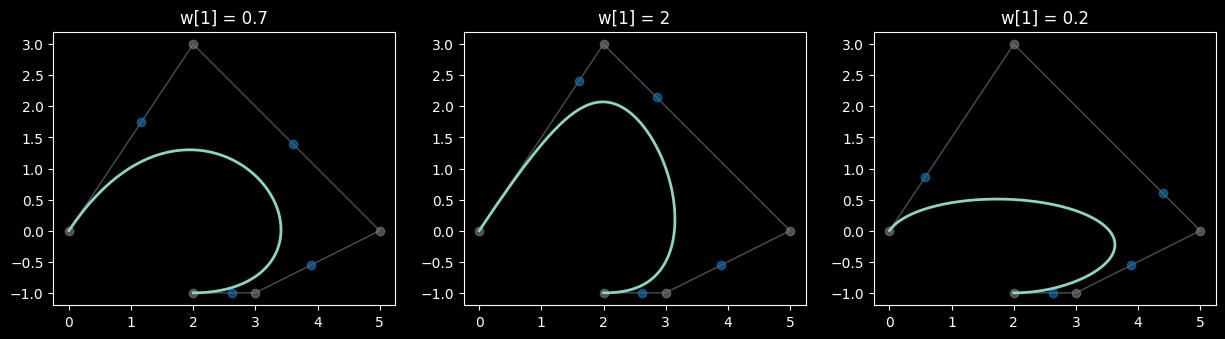

In [401]:
t = np.linspace(0, 1, 100)
plt.figure(figsize=(15,4))
plt.subplot(1, 3, 1)
plotrbezier(B, w1, t)
plt.title("w[1] = 0.7")
plt.subplot(1, 3, 2)
plotrbezier(B, w2, t)
plt.title("w[1] = 2")
plt.subplot(1, 3, 3)
plotrbezier(B, w3, t)
plt.title("w[1] = 0.2")